# ATiG 2026: LD score regression — answers
29 October 2026 · About 75 minutes · Work in pairs

We will read three published GWAS, match them to one LD reference, and use LD score
regression (LDSC) to estimate SNP heritability and genetic correlations.

Run the cells in order. Change the settings marked `# TRY` and discuss the questions.
The setup downloads about 240 MB of GWAS results. [Open in Colab](https://colab.research.google.com/github/bvilhjal/ATIG_2026/blob/main/teaching_days/2026-10-29/LDSC/LDSC_practical_answers.ipynb)
and choose File → Save a copy in Drive. Use a Python 3 runtime.

## Setup
Run the three cells. No editing needed. The first installs [PLDSC](https://github.com/bvilhjal/PLDSC),
which brings [allelign](https://github.com/bvilhjal/allelign) and the LD scores.
The download takes a minute or two.

In [ ]:
%pip install -q "pldsc @ git+https://github.com/bvilhjal/PLDSC@v0.1.0.dev5"

In [1]:
import hashlib
import urllib.request
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import allelign
from pldsc import load_ld_reference, ldsc_chi2_keep, ldsc_h2_sumstats, ldsc_rg_sumstats

plt.rcParams['figure.dpi'] = 110
pd.set_option('display.float_format', '{:.3f}'.format)

In [2]:
#@title Download the GWAS files (no editing needed)
SOURCES = {  # trait: (file name, URL, SHA-256 of the file used here)
    'BMI': ('bmi_giant_ukb_2018.txt.gz',
            'https://ftp.ebi.ac.uk/pub/databases/gwas/summary_statistics/'
            'GCST006001-GCST007000/GCST006900/Meta-analysis_Locke_et_al+UKBiobank_2018_UPDATED.txt.gz',
            '0d6ed0ea97870916b830ccae349df94ca6f3cc68c025c79e784729af7f7136a4'),
    'TG': ('tg_glgc_2013.txt.gz',
           'https://csg.sph.umich.edu/willer/public/lipids2013/jointGwasMc_TG.txt.gz',
           '37087a0015c3211f5696616ad276eb4b5fae7219e0b8a2f37a5ed86b626c5f0b'),
    'DBP': ('dbp_evangelou_2018.txt.gz',
            'https://ftp.ebi.ac.uk/pub/databases/gwas/summary_statistics/'
            'GCST006001-GCST007000/GCST006630/Evangelou_30224653_DBP.txt.gz',
            'c55cfc8b50abee8e13ef88d70ab52678b1f45b45cf5974bdab91f8c8b361fd59'),
}
folder = Path('gwas_downloads')
folder.mkdir(exist_ok=True)
paths = {}
for trait, (name, url, sha256) in SOURCES.items():
    path = folder / name
    if not path.exists():
        urllib.request.urlretrieve(url, folder / 'partial')
        (folder / 'partial').rename(path)
    if hashlib.sha256(path.read_bytes()).hexdigest() != sha256:
        raise ValueError(f'{path} is not the file used here; delete it and rerun')
    paths[trait] = path
    print(f'{trait}: {name}, {path.stat().st_size / 1e6:.0f} MB')

BMI: bmi_giant_ukb_2018.txt.gz, 47 MB
TG: tg_glgc_2013.txt.gz, 59 MB
DBP: dbp_evangelou_2018.txt.gz, 135 MB


## Q1. Look at the files

Each consortium uses its own format. Tables 1–3 show the first rows of each file.

- BMI: [Yengo et al. (2018)](https://pubmed.ncbi.nlm.nih.gov/30124842/), GIANT and UK Biobank, about 700,000 people.
- TG (triglycerides): [Willer et al. (2013)](https://pubmed.ncbi.nlm.nih.gov/24097068/), Global Lipids Genetics Consortium, about 90,000 people for most SNPs.
- DBP (diastolic blood pressure): [Evangelou et al. (2018)](https://pubmed.ncbi.nlm.nih.gov/30224653/), UK Biobank and ICBP, about 750,000 people.

For each file, find the effect allele, the other allele, the effect estimate, its standard
error, the sample size and the genomic position. Which file has no rsIDs? Which has no
position column? What else differs?

In [3]:
for number, (trait, path) in enumerate(paths.items(), start=1):
    print(f'Table {number}. The first rows of the {trait} file, as text.')
    display(pd.read_csv(path, sep=r'\s+', nrows=3, dtype=str))

Table 1. The first rows of the BMI file, as text.


,CHR,POS,SNP,Tested_Allele,Other_Allele,Freq_Tested_Allele_in_HRS,BETA,SE,P,N
0,7,92383888,rs10,A,C,0.06431,0.0013,0.0042,7.5e-01,598895
1,12,126890980,rs1000000,A,G,0.2219,0.0001,0.0021,9.6e-01,689928
2,4,21618674,rs10000010,T,C,0.5086,-0.0001,0.0016,9.4e-01,785319


Table 2. The first rows of the TG file, as text.


,SNP_hg18,SNP_hg19,rsid,A1,A2,beta,se,N,P-value,Freq.A1.1000G.EUR
0,chr10:10000135,chr10:9960129,rs4747841,a,g,0.0020,0.0047,90263.00,0.7567,0.4908
1,chr10:10000265,chr10:9960259,rs4749917,c,t,0.002,0.0047,90263.00,0.7612,0.4908
2,chr10:100002729,chr10:100012739,rs737656,a,g,0.0094,0.0048,91013.00,0.06856,0.3206


Table 3. The first rows of the DBP file, as text.


,MarkerName,Allele1,Allele2,Freq1,Effect,StdErr,P,TotalSampleSize,N_effective
0,10:100000625:SNP,a,g,0.5663,-0.0432,0.0174,0.01294,757601,756275
1,10:100000645:SNP,a,c,0.7935,0.0263,0.0214,0.218,757599,754442
2,10:100001867:SNP,t,c,0.0139,-0.0424,0.0839,0.6128,742538,595603


**Answer.** BMI: `Tested_Allele` is the effect allele, `Other_Allele` the other allele,
`BETA` and `SE` the estimate and its standard error, `N` the sample size, and `CHR` and
`POS` the position. TG: `A1`, `A2`, `beta`, `se` and `N`; the position is only available
as text in `SNP_hg19` (and `SNP_hg18`, on an older build). DBP: `Allele1`, `Allele2`,
`Effect`, `StdErr`, and two sample sizes; it has no rsIDs, and the position is part of
`MarkerName`.

Other differences: alleles are lower case in TG and DBP; the effect and standard-error
columns have three names each; the allele frequencies come from HRS, 1000 Genomes and the
study itself; all TG effects are positive, because GLGC reports the TG-raising allele as
`A1`; and the DBP effects are in mmHg while BMI effects are in SD units. Units do not matter here,
because LDSC only uses $z = \beta/\text{SE}$.

## Q2. Read the files

allelign recognises common column names and reads each file into the same layout.
Table 4 shows which columns it used. The DBP file has no rsIDs: its `MarkerName` is
chromosome:position:type on GRCh37, so we split it to get positions. DBP is then
matched by position.

Which fields were not found? For DBP, allelign used `N_effective` (sample size times
imputation quality) rather than `TotalSampleSize`. Why does the choice of N matter
for heritability?

In [4]:
mappings = {trait: allelign.inspect_columns(path)['mapping'] for trait, path in paths.items()}
print('Table 4. File columns used by allelign; blank if not found.')
display(pd.DataFrame(mappings).fillna(''))

Table 4. File columns used by allelign; blank if not found.


,BMI,TG,DBP
id,SNP,rsid,MarkerName
chrom,CHR,,
pos,POS,,
ea,Tested_Allele,A1,Allele1
oa,Other_Allele,A2,Allele2
beta,BETA,beta,Effect
se,SE,se,StdErr
pval,P,P-value,P
n_eff,N,N,N_effective
eaf,,,Freq1


In [5]:
gwas = {trait: allelign.read_sumstats(path) for trait, path in paths.items()}  # About 30 s.

# Chromosome and position from DBP's MarkerName, e.g. 10:100000625:SNP.
dbp = gwas['DBP']
marker = pd.Series(dbp.id).str.split(':', expand=True)
gwas['DBP'] = allelign.Sumstats(
    id=dbp.id, chrom=marker[0].to_numpy(), pos=marker[1].astype(int).to_numpy(),
    ea=dbp.ea, oa=dbp.oa, beta=dbp.beta, se=dbp.se, n_eff=dbp.n_eff, eaf=dbp.eaf, info=dbp.info)

for trait, sumstats in gwas.items():
    print(f'{trait}: {len(sumstats):,} variants, median N {np.median(sumstats.n_eff):,.0f}')

BMI: 2,336,269 variants, median N 688,566
TG: 2,439,432 variants, median N 90,996
DBP: 7,160,657 variants, median N 742,239


**Answer.** Chromosome and position were not found for TG and DBP, and allele frequency
was found only for DBP. TG is matched by rsID instead, and we take the DBP positions from
`MarkerName`. The frequency columns of BMI and TG come from other samples (HRS,
1000 Genomes), so it is just as well that they are not used.

The LDSC slope is $Nh^2/M$, so $h^2$ is estimated as slope × $M/N$: an N that is 10%
too large gives an $h^2$ about 10% too small. `N_effective` discounts poorly imputed
SNPs. Its median is 742,239 against 756,595 for `TotalSampleSize`. The HapMap3 SNPs are
well imputed (at least 61% of the total N, median 99%), so here the choice matters little:
with `TotalSampleSize`, DBP's h² is 0.136 instead of 0.137.

## Q3. Match to the LD reference

LDSC needs an LD score for every SNP. We use scores for about 1.2 million HapMap3 SNPs,
calculated from 489 Europeans in the 1000 Genomes Project; they come with PLDSC. PLDSC
leaves out about 30,000 of them that lie in regions with unusually long-range LD, such
as the MHC.
allelign first removes duplicates and variants with low sample size. It then aligns each
GWAS to the reference allele `a1`, changing the sign when a file's effect allele is `a2`
(Table 5).

Why is only a small part of the DBP file used? Table 6 follows rs1421085 in *FTO*
through the three files. Why must all traits refer to the same allele before we
correlate them?

In [6]:
ref = load_ld_reference('hm3-eur')
print(ref)

aligned = {}
counts = {}
for trait, sumstats in gwas.items():
    keep, qc = allelign.qc_sumstats(sumstats)
    aligned[trait] = allelign.harmonize(sumstats.subset(keep), ref.variants)
    log = aligned[trait].log
    counts[trait] = {'in file': len(sumstats), 'after QC': qc['n_kept'],
                     'matched': log['n_matched'], 'sign changed': log['n_flipped']}
print('Table 5. Variants kept at each step.')
display(pd.DataFrame(counts))

LDReference('hm3-eur': 1159831 variants, m_snps=9997231, EUR, GRCh37)


Table 5. Variants kept at each step.


,BMI,TG,DBP
in file,2336269,2439432,7160657
after QC,2336251,2400520,7159430
matched,986154,994304,1133898
sign changed,461674,497542,531032


In [7]:
snp = 'rs1421085'  # TRY: rs1260326 (GCKR) or rs13107325 (SLC39A8)
row = np.flatnonzero(ref.variants.id == snp)[0]
chrom, pos = ref.variants.chrom[row], ref.variants.pos[row]
print(f'{snp}: chromosome {chrom}, position {pos:,}; '
      f'reference a1 = {ref.variants.a1[row]}, a2 = {ref.variants.a2[row]}')

rows = {}
for trait, sumstats in gwas.items():
    # rsID for BMI and TG, position for DBP.
    i = np.flatnonzero((sumstats.id == snp) | ((sumstats.chrom == chrom) & (sumstats.pos == pos)))[0]
    j = np.flatnonzero(aligned[trait].var_index == row)[0]
    rows[trait] = {'effect allele': sumstats.ea[i], 'other allele': sumstats.oa[i],
                   'z in file': sumstats.beta[i] / sumstats.se[i],
                   'z for a1': aligned[trait].beta[j] / aligned[trait].se[j]}
snp_table = pd.DataFrame(rows).T.astype({'z in file': float, 'z for a1': float})
print(f'Table 6. {snp} in the three GWAS.')
display(snp_table)

rs1421085: chromosome 16, position 53,800,954; reference a1 = C, a2 = T


Table 6. rs1421085 in the three GWAS.


,effect allele,other allele,z in file,z for a1
BMI,T,C,-45.765,45.765
TG,C,T,5.057,5.057
DBP,T,C,3.650,-3.650


**Answer.** LDSC uses only the HapMap3 SNPs, which are common, well imputed and have LD
scores. That is 1.13 of the 7.16 million DBP variants (16%), against 41–42% of the
BMI and TG files. In QC, TG loses 37,752 variants with N below 70% of the median and
1,160 rows whose rsID appears more than once.

The BMI file reports rs1421085 for allele T with z = −45.8. For the reference allele C,
that becomes +45.8: C raises BMI. TG reports C already (z = 5.1), so C also raises
triglycerides. Bivariate LDSC multiplies the two z scores of each SNP. About half of
the SNPs change sign in each file, so without alignment the products would have
random signs, and the genetic covariance would be pulled towards zero. DBP reports
T (z = 3.65), so the BMI-raising C allele lowers DBP in this GWAS. Keep this in mind
for Q6.

## Q4. Estimate SNP heritability

LDSC models the expected χ² statistic of SNP $j$ as

$$E[\chi^2_j] = 1 + Na + \frac{N h^2}{M}\,\ell_j, \qquad (1)$$

where $\ell_j$ is its LD score, $N$ the sample size, $M$ the number of SNPs the
heritability $h^2$ refers to, and $a$ the inflation from confounding, such as population
stratification. Figure 1 shows the mean χ² against LD score; Table 7 has the fits.

Which trait has the highest heritability? Compare each intercept with λGC, the median χ²
divided by 0.455 (the median expected without any association). Which tells you more
about confounding? Why might TG's intercept be below one? Then set `M = ref.m_snps` and
rerun both cells. What changes, and what does not?

In [8]:
M = ref.m_snps_5_50  # SNPs with MAF 5–50%, as in the original LDSC. TRY: ref.m_snps

fits = {trait: ldsc_h2_sumstats(sumstats, ref.variants, ref.scores, m_snps=M).estimate
        for trait, sumstats in gwas.items()}  # About 30 s.

table = {}
for trait, fit in fits.items():
    z = aligned[trait].beta / aligned[trait].se
    table[trait] = {'h2': fit.h2, 'SE': fit.h2_se, 'intercept': fit.intercept,
                    'intercept SE': fit.intercept_se, 'mean chi2': fit.mean_chisq,
                    'lambda GC': allelign.genomic_inflation(z=z)}
print(f'Table 7. SNP heritability with M = {M:,}.')
display(pd.DataFrame(table).T)

Table 7. SNP heritability with M = 5,961,159.


,h2,SE,intercept,intercept SE,mean chi2,lambda GC
BMI,0.214,0.008,1.159,0.032,3.817,2.714
TG,0.176,0.022,0.955,0.012,1.212,1.117
DBP,0.137,0.007,1.211,0.033,3.009,2.012


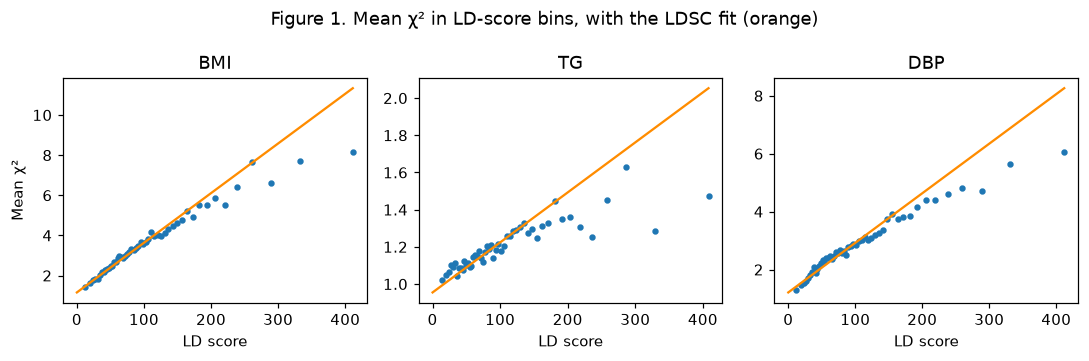

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(10, 3.3))
for ax, (trait, fit) in zip(axes, fits.items()):
    h = aligned[trait]
    chi2 = (h.beta / h.se)**2
    used = ldsc_chi2_keep(chi2, h.n_eff)[0]  # The fit drops SNPs with very large chi2.
    snps = pd.DataFrame({'ld_score': ref.scores[h.var_index][used], 'chi2': chi2[used]})
    snps = snps[snps['ld_score'] < snps['ld_score'].quantile(0.99)]  # Readable x-axis.
    snps['bin'] = pd.qcut(snps['ld_score'], 50, labels=False)  # 50 bins of equal size.
    means = snps.groupby('bin').mean()
    ax.scatter(means['ld_score'], means['chi2'], s=10)

    # Equation (1) with the fitted intercept and h2, at the median sample size.
    grid = np.linspace(0, means['ld_score'].max(), 100)
    ax.plot(grid, fit.intercept + np.median(h.n_eff) * fit.h2 / M * grid, color='darkorange')
    ax.set_title(trait)
    ax.set_xlabel('LD score')
axes[0].set_ylabel('Mean χ²')
fig.suptitle('Figure 1. Mean χ² in LD-score bins, with the LDSC fit (orange)')
plt.tight_layout()
plt.show()

**Answer.** With the common-SNP M, BMI has the highest heritability (0.214, SE 0.008),
followed by TG (0.176, SE 0.022) and DBP (0.137, SE 0.007). In Figure 1, mean χ²
rises almost linearly with LD score, as equation (1) predicts. In the last few bins the
points fall below the line for all three traits; the regression weights give SNPs with
high LD scores little weight, so the fit follows the bulk of the SNPs. TG is noisier
because its N is about eight times smaller.

λGC is 2.7 for BMI, but the intercept is only 1.159. In 690,000 people a polygenic
trait inflates χ² everywhere, and λGC cannot separate that from confounding. The
intercept can: about 6% of the excess mean χ² for BMI, (1.159 − 1)/(3.817 − 1), and
10% for DBP, is in the intercept. That is an upper bound on confounding, because the
intercept also absorbs mismatch between the model or the LD reference and the data.
Note also that the UK Biobank part of DBP had already been divided by its own LDSC
intercept.

TG's intercept is 0.955 (SE 0.012), below one. GLGC corrected each study for genomic
control, which divides all χ² by λGC and lowers both the intercept and the slope, so
TG's $h^2$ is underestimated. The P-values in the file were corrected a second time:
their χ² are about 11% smaller than those from beta/SE, which we use.

TG's $h^2$ also depends on a few loci with very large effects, which equation (1) does
not describe well. The fit drops SNPs with χ² above max(80, N/1000), which is 342 SNPs
for TG. Without that filter (`chi2_cap=False`), TG's $h^2$ is 0.29. The original LDSC
software handles these SNPs with a two-step estimator instead.

With `M = ref.m_snps` (9,997,231 variants), every $h^2$ is 1.68 times larger: 0.36,
0.30 and 0.23. The intercepts, mean χ² and λGC do not change, and neither would $r_g$.
M decides what $h^2$ refers to: the common SNPs (MAF 5–50%) of the reference panel,
or all 10 million variants, assuming rare variants explain as much per standardised
variant as common ones. Published LDSC estimates normally use the common-SNP M.

## Q5. Genetic correlation between BMI and TG

Bivariate LDSC uses the product of the two traits' z scores:

$$E[z_{1j} z_{2j}] = \frac{\sqrt{N_1 N_2}\,\rho_g}{M}\,\ell_j + \frac{N_s\,\rho}{\sqrt{N_1 N_2}}, \qquad (2)$$

where $\rho_g$ is the genetic covariance, $N_s$ the number of people in both GWAS and
$\rho$ the phenotypic correlation among them. The genetic correlation is
$r_g = \rho_g / \sqrt{h^2_1 h^2_2}$.

Is the BMI–TG genetic correlation clearly different from zero? What does the cross-trait
intercept tell you? The plain correlation of z scores across SNPs is much smaller than
$r_g$. Why?

In [10]:
pair = ('BMI', 'TG')
fit = ldsc_rg_sumstats(gwas[pair[0]], gwas[pair[1]], ref.variants, ref.scores,
                       m_snps=M, ncores=2).estimate
print(f'{pair[0]}–{pair[1]} genetic correlation: {fit.rg:.3f} (SE {fit.rg_se:.3f})')
print(f'Genetic covariance: {fit.gcov:.4f}')
print(f'Cross-trait intercept: {fit.gcov_intercept:.3f} (SE {fit.gcov_intercept_se:.3f})')

# For comparison: the plain correlation of z scores, ignoring LD.
shared, i, j = np.intersect1d(aligned[pair[0]].var_index, aligned[pair[1]].var_index,
                              return_indices=True)
z1 = aligned[pair[0]].beta[i] / aligned[pair[0]].se[i]
z2 = aligned[pair[1]].beta[j] / aligned[pair[1]].se[j]
print(f'Correlation of z scores over {len(shared):,} SNPs: {np.corrcoef(z1, z2)[0, 1]:.3f}')

BMI–TG genetic correlation: 0.282 (SE 0.030)
Genetic covariance: 0.0543
Cross-trait intercept: 0.051 (SE 0.011)
Correlation of z scores over 941,293 SNPs: 0.126


**Answer.** $r_g$ = 0.282 (SE 0.030), more than nine standard errors from zero. Variants that
raise BMI tend to raise triglycerides.

The cross-trait intercept is 0.051 (SE 0.011). From equation (2), it reflects people in
both GWAS (many cohorts contributed to both GIANT and GLGC) or confounding shared by
the two. If the phenotypic correlation is around 0.3, it corresponds to roughly
0.051 × √(688,566 × 90,996) / 0.3 ≈ 43,000 shared participants. Because the intercept is
estimated, the overlap does not bias $r_g$.

The plain correlation of z scores is 0.126. It is diluted by sampling noise: TG's mean
χ² is only 1.21, so most of the variance of its z scores is noise. Averaging equation (2)
over SNPs gives roughly
[0.282 × √((3.817 − 1.159)(1.212 − 0.955)) + 0.051] / √(3.817 × 1.212) ≈ 0.13,
close to what we see. LDSC uses only the part of $z_1 z_2$ that grows with LD score,
which is genetic.

## Q6. Add blood pressure

Table 8 shows all three pairs. UK Biobank is part of both the BMI and the DBP GWAS.
Evangelou et al. analysed blood pressure adjusted for age, sex and BMI.

Is the BMI–DBP result what you expected? How can adjusting DBP for BMI change its genetic
correlation with BMI? Why is the BMI–DBP cross-trait intercept close to zero despite the
overlap?

In [11]:
pairs = [('BMI', 'TG'), ('BMI', 'DBP'), ('TG', 'DBP')]
table = {}
for trait1, trait2 in pairs:  # About a minute.
    estimate = ldsc_rg_sumstats(gwas[trait1], gwas[trait2], ref.variants, ref.scores,
                                m_snps=M, ncores=2).estimate
    table[f'{trait1}–{trait2}'] = {'rg': estimate.rg, 'SE': estimate.rg_se,
                                   'cross-trait intercept': estimate.gcov_intercept,
                                   'intercept SE': estimate.gcov_intercept_se}
print('Table 8. Genetic correlations.')
display(pd.DataFrame(table).T)

Table 8. Genetic correlations.


,rg,SE,cross-trait intercept,intercept SE
BMI–TG,0.282,0.030,0.051,0.011
BMI–DBP,-0.059,0.017,0.003,0.014
TG–DBP,0.095,0.027,0.036,0.011


**Answer.** Higher BMI goes with higher blood pressure, so for unadjusted DBP a positive
$r_g$ would be expected. Here BMI–DBP $r_g$ is −0.059 (SE 0.017). Adjusted for BMI, each
SNP's DBP estimate is roughly its DBP effect minus $b$ times its BMI effect, where $b$
is the observational regression of DBP on BMI. Subtracting a multiple of the BMI genetic
effects pushes the genetic covariance with BMI down, here to slightly below zero. This is
collider bias from adjusting for a heritable covariate
([Aschard et al. 2015](https://pubmed.ncbi.nlm.nih.gov/25640676/)); Evangelou et al. mention
the risk. Table 6 showed this at one SNP: the BMI-raising allele of
rs1421085 lowers BMI-adjusted DBP (z = −3.65).

The cross-trait intercept is $N_s\rho/\sqrt{N_1 N_2}$. Within UK Biobank, DBP adjusted for
BMI is uncorrelated with BMI by construction, so $\rho \approx 0$ and the large overlap
leaves no trace: 0.003 (SE 0.014). TG–DBP gives $r_g$ = 0.095 (SE 0.027).

## Q7. Conclude

Write three sentences: report the BMI–TG genetic correlation with its standard error,
explain why it does not show that higher BMI raises triglycerides, and say what the
BMI–DBP result teaches you about using published GWAS results.

**Answer.** The genetic correlation between BMI and triglycerides is 0.28 (SE 0.03),
estimated from about one million HapMap3 SNPs. It does not tell whether BMI raises
triglycerides, triglyceride-related biology affects BMI, the same variants affect both
through separate pathways, or both traits depend on something else; MR or other
designs are needed for that. The BMI–DBP estimate shows that a covariate in a
published GWAS changes what is estimated, so read the methods before combining
summary statistics.

## Going further (optional)

**More traits.** The cell below adds one more GWAS in a format you have already read:
other lipids from the same consortium as TG, or height from the same study as BMI.
It fits its heritability and its genetic correlations with BMI, TG and DBP. Which
pairs would you expect to be correlated? Look for other European-ancestry GWAS with
rsIDs or GRCh37 positions, for example in the [GWAS Catalog](https://www.ebi.ac.uk/gwas/downloads/summary-statistics),
and add them in the same way. Check `allelign.inspect_columns` first.

**Ask an AI model to implement LDSC.** Give an AI assistant (Claude, ChatGPT or another)
the aligned data for one trait and ask for univariate LDSC from scratch in NumPy,
with LDSC's regression weights and a block-jackknife standard error:

```python
h = aligned['BMI']
z, n, ell = h.beta / h.se, h.n_eff, ref.scores[h.var_index]
```

Compare its $h^2$ and intercept with Table 7. Then read the code: which M does it use,
how are the weights defined, and what happens to SNPs with very large χ²? Can you make
it agree with PLDSC? Then try bivariate LDSC.

In [ ]:
MORE = {  # Same formats as TG and BMI.
    'HDL': 'https://csg.sph.umich.edu/willer/public/lipids2013/jointGwasMc_HDL.txt.gz',
    'LDL': 'https://csg.sph.umich.edu/willer/public/lipids2013/jointGwasMc_LDL.txt.gz',
    'TC': 'https://csg.sph.umich.edu/willer/public/lipids2013/jointGwasMc_TC.txt.gz',
    'Height': 'https://ftp.ebi.ac.uk/pub/databases/gwas/summary_statistics/'
              'GCST006001-GCST007000/GCST006901/Meta-analysis_Wood_et_al+UKBiobank_2018.txt.gz',
}
trait = 'HDL'  # TRY: 'LDL', 'TC' or 'Height'
path = folder / MORE[trait].split('/')[-1]
if not path.exists():
    urllib.request.urlretrieve(MORE[trait], folder / 'partial')
    (folder / 'partial').rename(path)
gwas[trait] = allelign.read_sumstats(path)
print(trait, ldsc_h2_sumstats(gwas[trait], ref.variants, ref.scores, m_snps=M).estimate)
for other in ('BMI', 'TG', 'DBP'):
    fit = ldsc_rg_sumstats(gwas[other], gwas[trait], ref.variants, ref.scores,
                           m_snps=M, ncores=2).estimate
    print(f'{other}–{trait}: rg {fit.rg:.3f} (SE {fit.rg_se:.3f})')

## Data and method notes

The GWAS files are downloaded and checked against the SHA-256 checksums in the setup cell.
All three are meta-analyses of European-ancestry samples with GRCh37 positions. BMI (GIANT)
and DBP (discovery stage) come from the GWAS Catalog
([GCST006900](https://www.ebi.ac.uk/gwas/studies/GCST006900),
[GCST006630](https://www.ebi.ac.uk/gwas/studies/GCST006630)), TG from the
[Global Lipids Genetics Consortium](https://csg.sph.umich.edu/willer/public/lipids2013/)
(joint GWAS and Metabochip analysis). The TG studies were corrected for genomic control,
and the meta-analysis P values were corrected again. For DBP, the UK Biobank statistics
were divided by their LDSC intercept (1.219) and the ICBP studies corrected for genomic
control before the meta-analysis. Further details are in [`data/sources.json`](data/sources.json).

The LD scores are the 1000 Genomes Phase 3 European scores for HapMap3 SNPs released with
LDSC ([Zenodo 7768714](https://doi.org/10.5281/zenodo.7768714)), packaged in PLDSC as
`hm3-eur`. The set has almost no strand-ambiguous A/T or C/G SNPs (4 of 1.19 million),
and allelign drops those. PLDSC fits equations (1) and (2) in one step, after dropping SNPs
with χ² above max(80, N/1000), and uses these LD scores for the regression weights; standard
errors come from a block jackknife. PLDSC leaves out allelign's GRCh37 long-range LD
regions by default (`load_ld_reference('hm3-eur', include_long_range_ld=True)` keeps them).
The original LDSC software instead uses a two-step estimator, and its regression weights
leave out only the MHC. Its estimates differ
somewhat from these, most for TG, whose h² depends on how SNPs with very large χ² are
handled. The plain z-score correlation in Q5 is shown only for contrast.

Background: [Bulik-Sullivan et al. (2015a)](https://pubmed.ncbi.nlm.nih.gov/25642630/) on LDSC
and [Bulik-Sullivan et al. (2015b)](https://pubmed.ncbi.nlm.nih.gov/26414676/) on genetic
correlation.